#Exploratory Data Analiysis

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns

In [2]:
df = pd.read_csv("archive/ai_jobs_salaries_clean.csv")

In [3]:
#estudo do formato
print(df.shape)
print(df.head())
print(df.columns)
print(df.info())

(71913, 17)
   work_year experience_level employment_type       job_title  salary  \
0       2025               EX              FT    Head of Data  348516   
1       2025               EX              FT    Head of Data  232344   
2       2025               SE              FT  Data Scientist  145400   
3       2025               SE              FT  Data Scientist   81600   
4       2025               MI              FT        Engineer  160000   

  salary_currency  salary_in_usd employee_residence  remote_ratio  \
0             USD         348516                 US             0   
1             USD         232344                 US             0   
2             USD         145400                 US             0   
3             USD          81600                 US             0   
4             USD         160000                 US           100   

  company_location company_size experience_level_label employment_type_label  \
0               US            M        Executive-level

In [4]:
df.describe()


,work_year,salary,salary_in_usd,remote_ratio
count,71913.000000,7.191300e+04,71913.000000,71913.000000
mean,2024.425153,1.617102e+05,151161.252625,24.569271
std,0.721198,2.872868e+05,77329.594122,42.917779
min,2020.000000,1.400000e+04,15000.000000,0.000000
25%,2024.000000,9.640000e+04,96000.000000,0.000000
50%,2025.000000,1.397000e+05,138750.000000,0.000000
75%,2025.000000,1.922000e+05,190315.000000,0.000000
max,2025.000000,3.040000e+07,800000.000000,100.000000


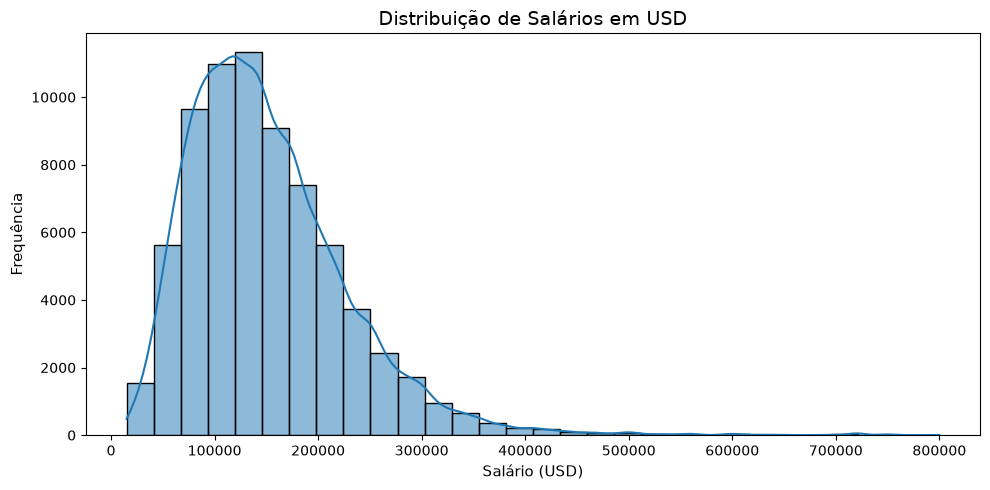

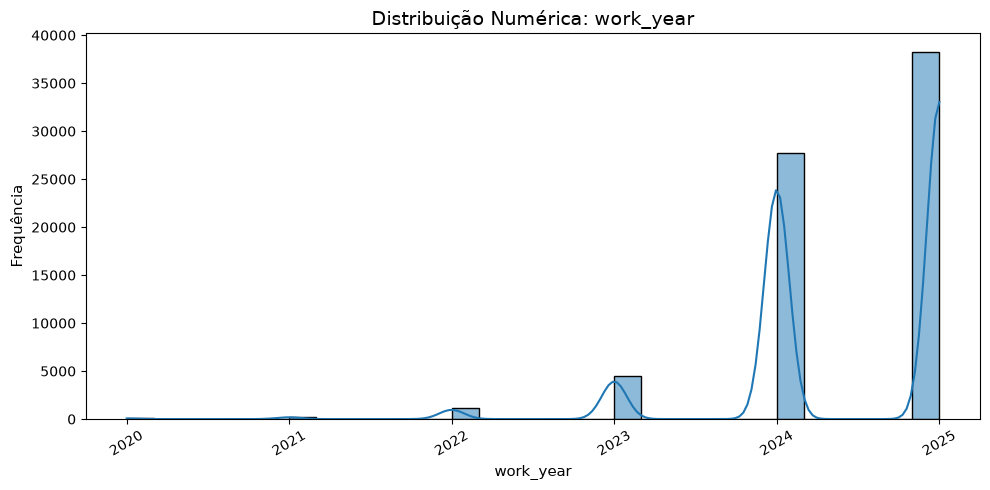

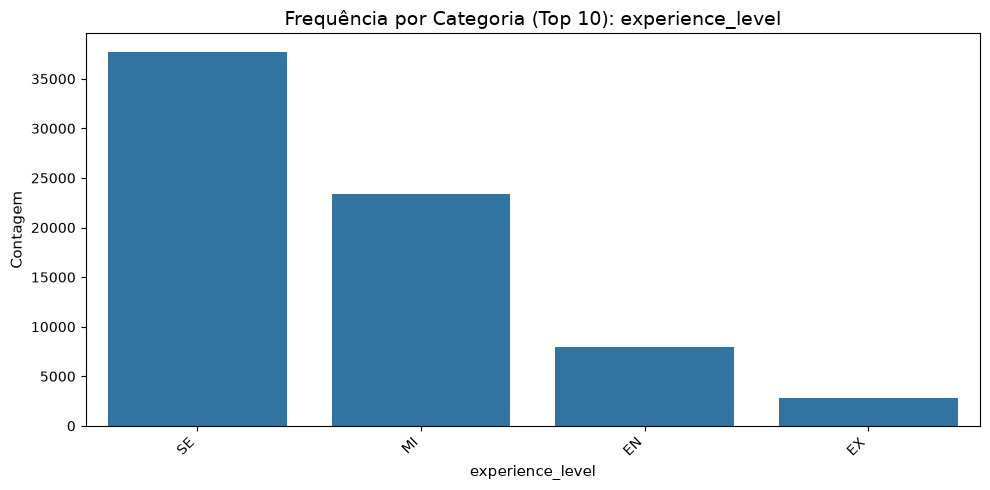

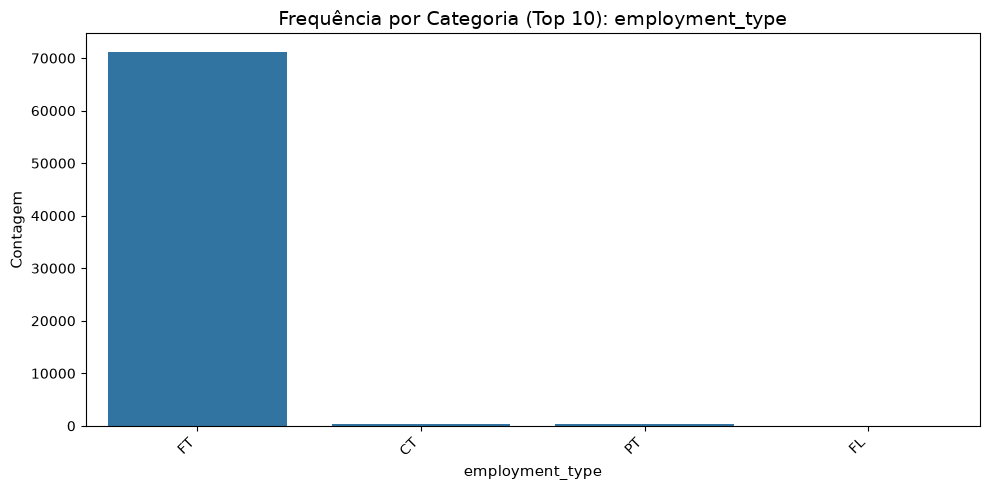

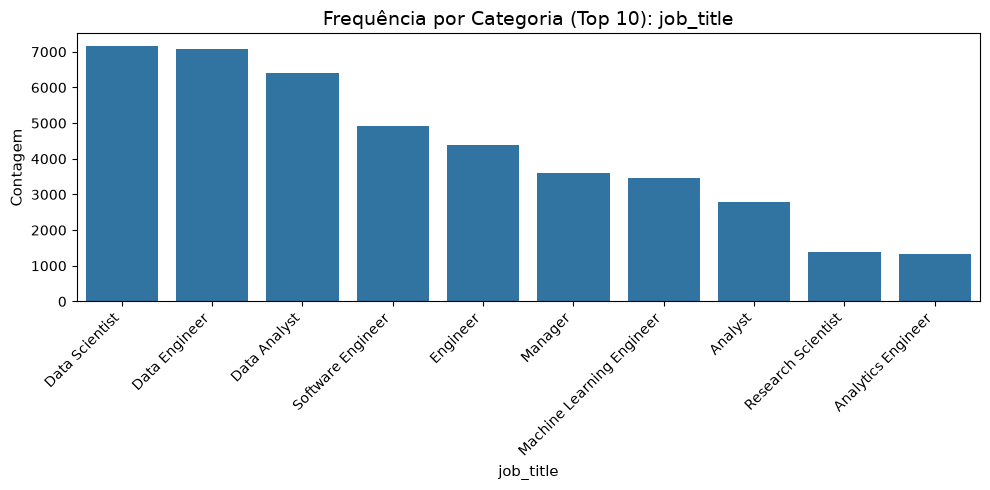

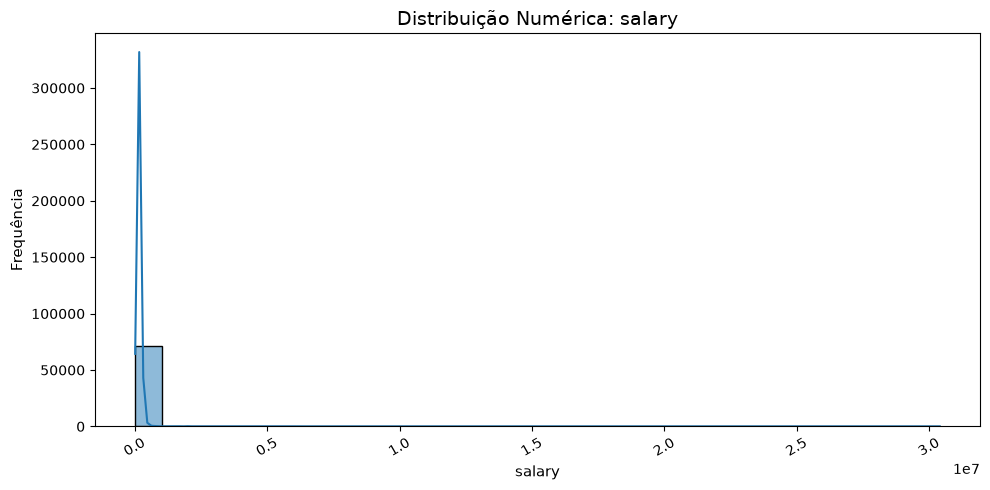

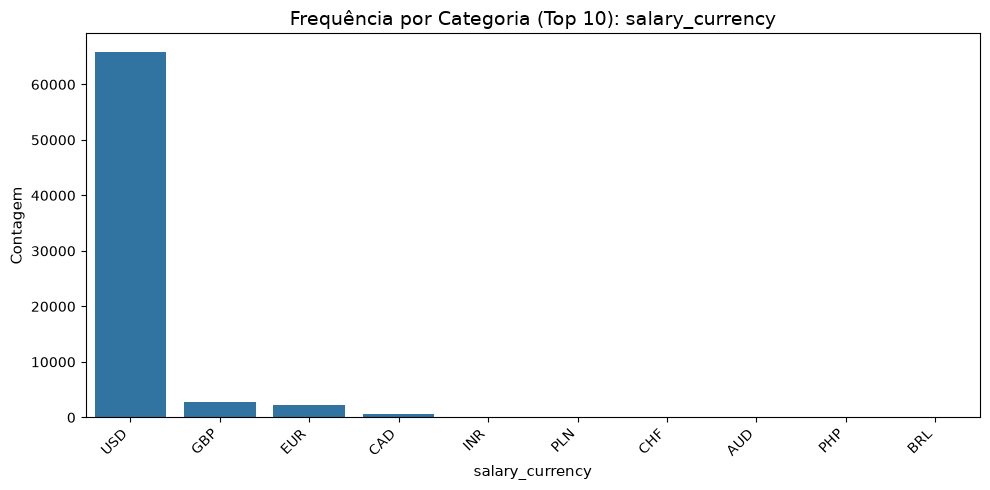

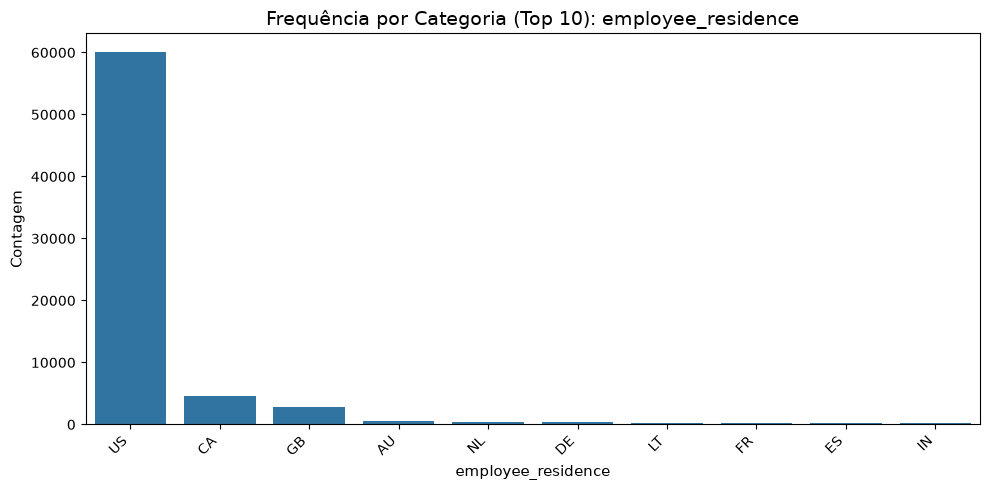

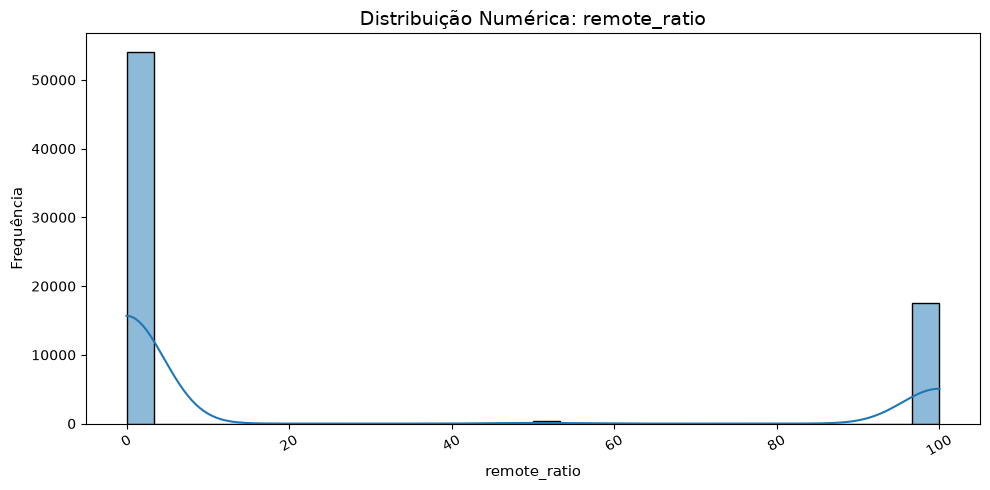

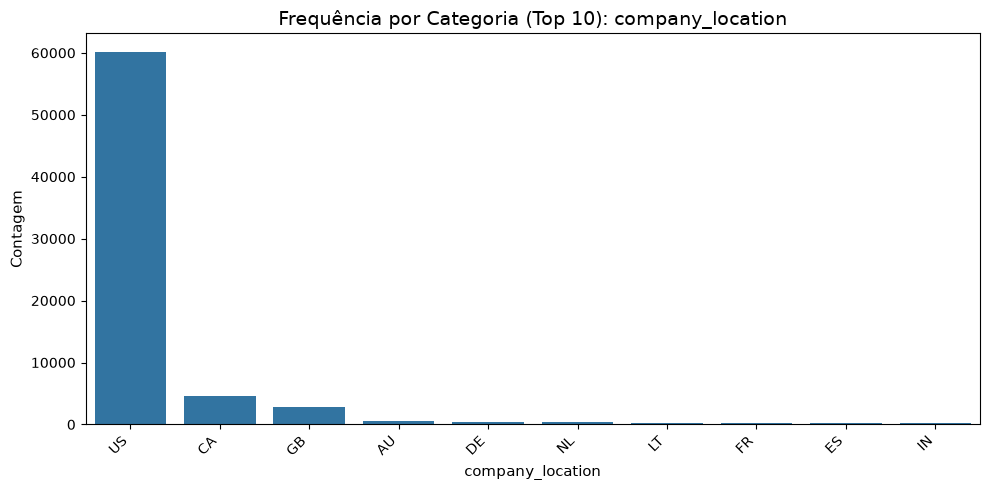

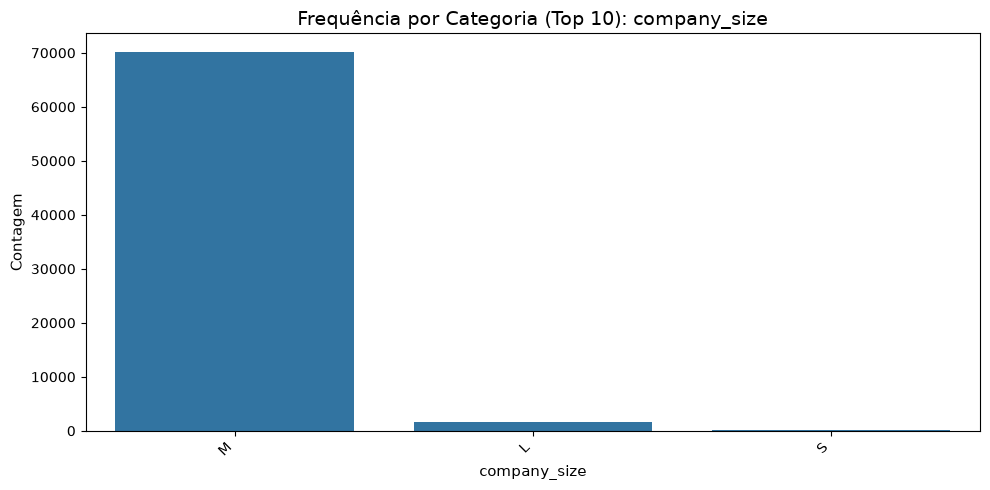

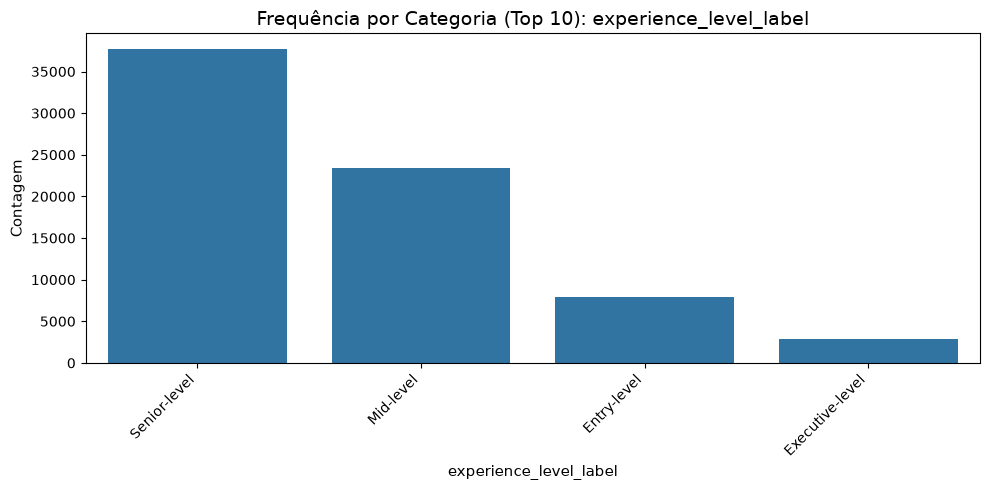

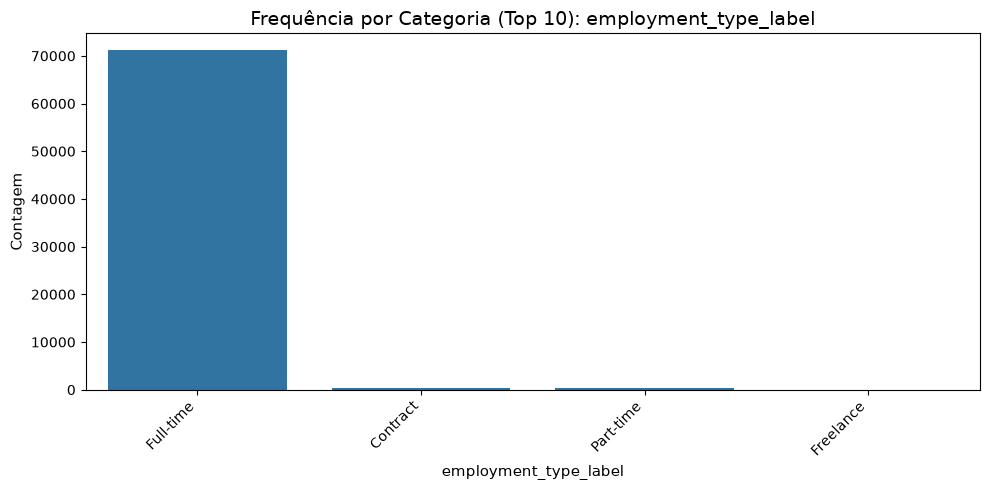

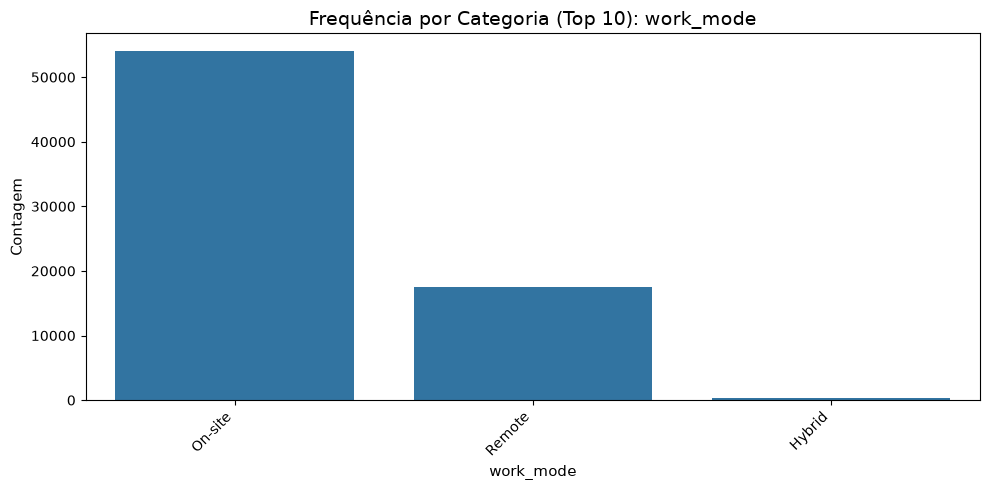

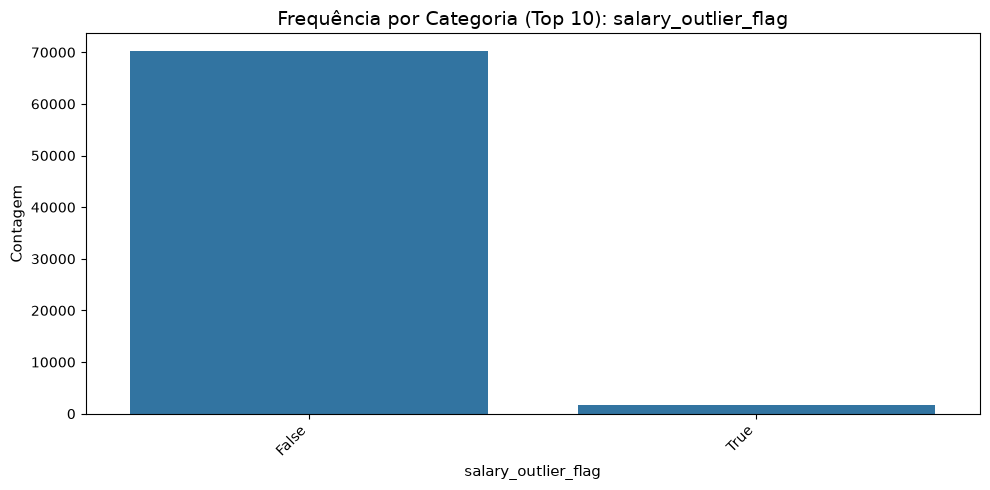

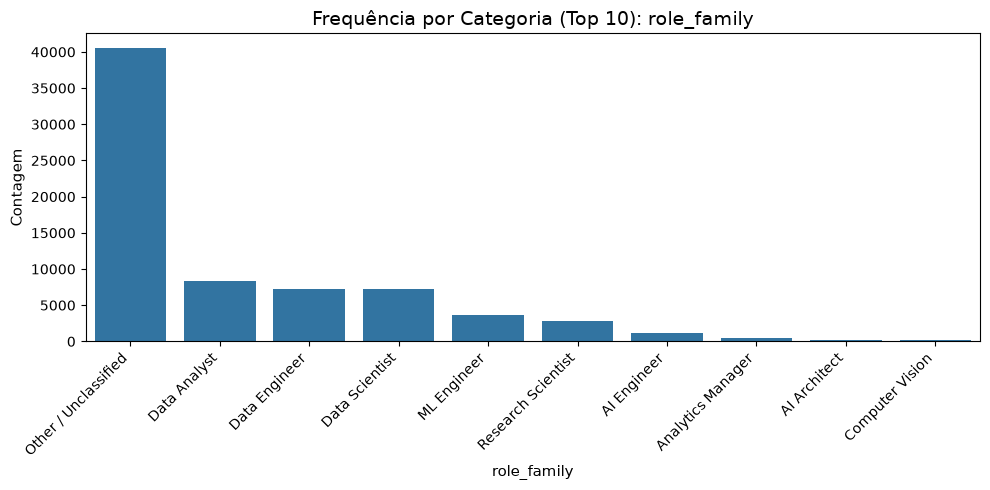

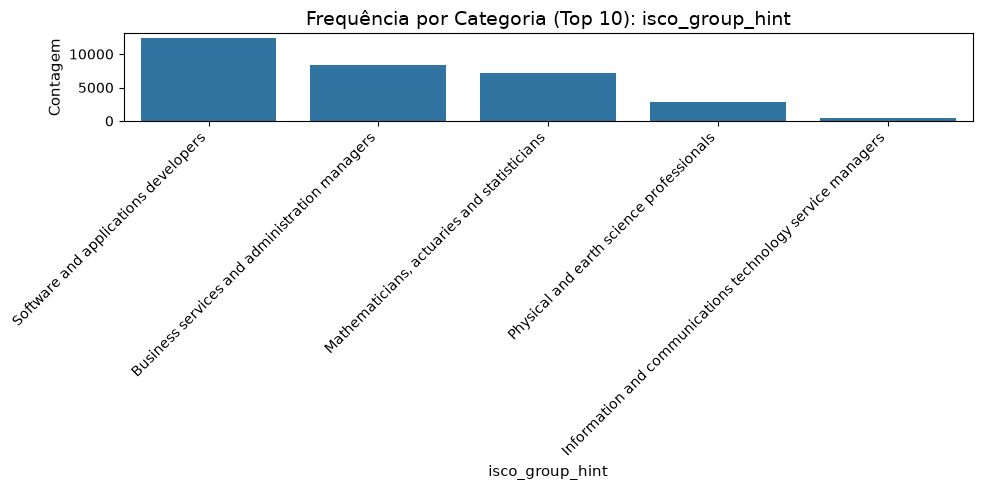

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Gráfico individual para 'salary_in_usd'
plt.figure(figsize=(10, 5))
sns.histplot(df['salary_in_usd'], bins=30, kde=True)
plt.title("Distribuição de Salários em USD", fontsize=14)
plt.xlabel("Salário (USD)", fontsize=11)
plt.ylabel("Frequência", fontsize=11)
plt.tight_layout()
plt.show()

# 2. Loop inteligente separando por tipo de dado
for col in df.columns:
    if col == 'salary_in_usd':
        continue  # Já plotado acima
        
    plt.figure(figsize=(10, 5))
    
    # Se a coluna for numérica (int ou float) -> Histogram
    if df[col].dtype in ['int64', 'float64']:
        sns.histplot(df[col], bins=30, kde=True)
        plt.title(f"Distribuição Numérica: {col}", fontsize=14)
        plt.xlabel(col, fontsize=11)
        plt.ylabel("Frequência", fontsize=11)
        plt.xticks(rotation=30)
        
    # Se a coluna for categórica (texto/object) -> Countplot ordenado
    else:
        # Pega as top 10 categorias mais frequentes para não poluir
        top_order = df[col].value_counts().head(10).index
        sns.countplot(data=df, x=col, order=top_order)
        plt.title(f"Frequência por Categoria (Top 10): {col}", fontsize=14)
        plt.xlabel(col, fontsize=11)
        plt.ylabel("Contagem", fontsize=11)
        plt.xticks(rotation=45, ha='right', fontsize=10) # Rotaciona e alinha os textos
        
    plt.tight_layout() # Evita corte de legendas e títulos
    plt.show() # Garante a renderização individual limpa no notebook

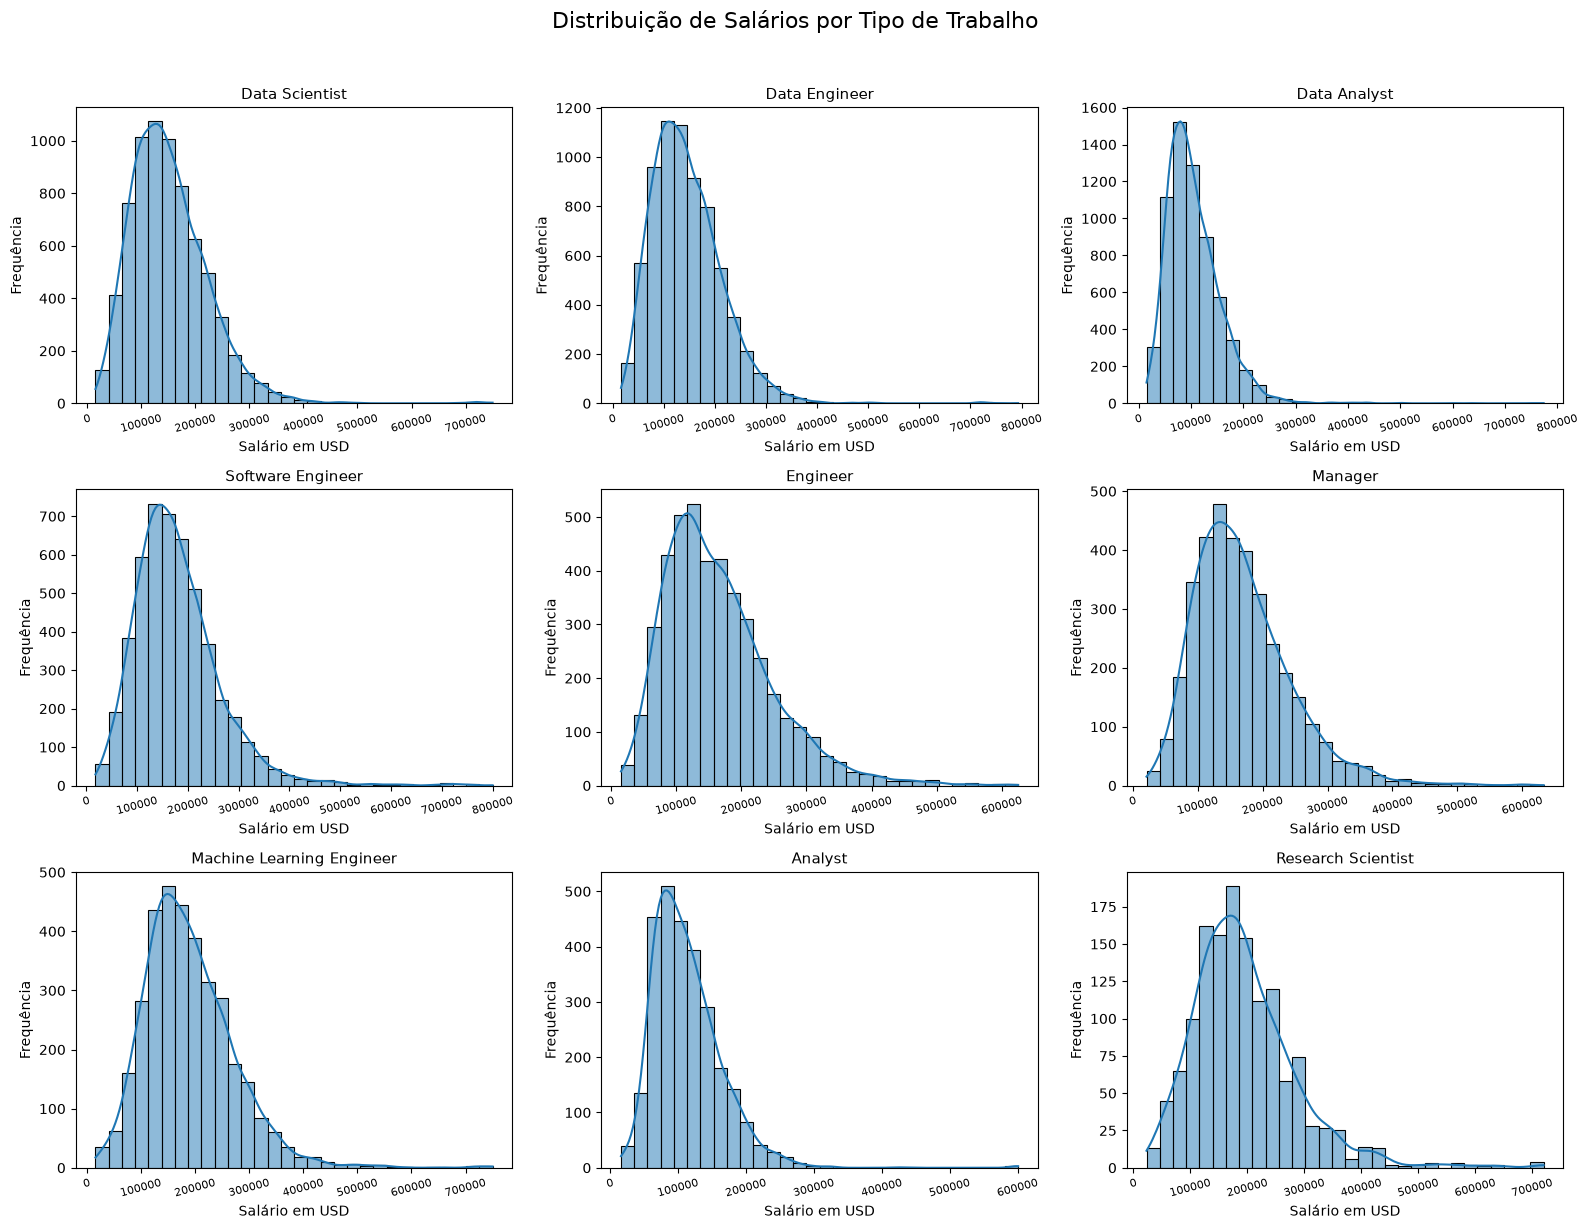

In [7]:
import warnings
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

# Pega as 9 categorias mais frequentes
categories = df['job_title'].value_counts().head(9).index

plt.figure(figsize=(16, 12)) # Aumenta o tamanho da imagem
plt.suptitle("Distribuição de Salários por Tipo de Trabalho", fontsize=16, y=1.02)

for i, category in enumerate(categories):
    plt.subplot(3, 3, i + 1)
    sns.histplot(df[df['job_title'] == category]['salary_in_usd'], bins=30, kde=True)
    plt.title(category, fontsize=11)
    plt.xlabel("Salário em USD", fontsize=10)
    plt.ylabel("Frequência", fontsize=10)
    plt.xticks(rotation=15, fontsize=8) # Rotaciona os números do eixo X para não encavalar

plt.tight_layout() # Corrige a sobreposição de títulos e eixos
plt.show()